# Predicción de Precios de Casas 🏠
### Proyecto universitario de Inteligencia Artificial — Regresión tabular

| | |
|---|---|
| **Autor** | _Tu nombre_ (matrícula: _XXXXXXXX_) |
| **Fecha** | Noviembre 2026 |
| **Objetivo** | Estimar el **precio continuo** de una vivienda a partir de sus características (habitaciones, baños, área, año de construcción, garaje, jardín y ubicación). |
| **Tipo de problema** | Aprendizaje supervisado — **regresión** |
| **Reproducibilidad** | Semilla fija `SEMILLA = 42` en todo el notebook |
| **Stack** | Python · pandas · scikit-learn · matplotlib · seaborn · Folium · Streamlit |

---

## Índice de contenidos

1. **Datos** — prototipo de 10 filas, carga del dataset (real + respaldo sintético), exploración, nulos, codificación y split anti-fuga.
2. **Modelos** — Regresión Lineal (base), Random Forest, Ridge y Lasso con `GridSearchCV`.
3. **Métricas** — RMSE, MAE y R² en tabla comparativa e interpretación.
4. **Análisis de residuos** del mejor modelo (4 gráficos interpretados).
5. **Importancia de características** (MDI, permutación y coeficientes) + informe.
6. **Mapa interactivo de precios por zona** (Folium).
7. **Exportación del modelo** (`joblib`) + **app.py** en Streamlit.
8. **Ejecución completa** — `requirements.txt`, comandos y estructura de carpetas.
9. **Conclusiones y defensa del proyecto** (preguntas típicas).

> 💡 **Cómo defender el proyecto:** cada sección explica *qué* se hace, *por qué* y *cómo se interpreta*. Lee las celdas Markdown antes de las de código.

> **Orden de lectura/ejecución:** de arriba hacia abajo, sin saltar celdas. Las celdas más pesadas (`GridSearchCV` con 5-fold) tardan unos segundos.

## 0. Configuración del entorno

**Qué se hace:** importamos todas las librerías, fijamos la semilla aleatoria y configuramos la estética de los gráficos.

**Por qué importa:**

- `SEMILLA = 42` → el generador sintético, el split `train/test` y los modelos aleatorizados (los bosques) producen **siempre el mismo resultado**. Sin semilla, el notebook no sería reproducible.
- `%matplotlib inline` → los gráficos se dibujan directamente en el notebook.
- `warnings.filterwarnings('ignore')` → silencia avisos benignos de versiones de librerías para que la salida sea limpia de cara a la defensa (en producción real NO conviene ignorar todos los warnings).

**Cómo interpretar:** la celda imprime las versiones instaladas. Si tu versión de `scikit-learn` es **≥ 1.4**, `root_mean_squared_error` y el scoring `neg_root_mean_squared_error` existen (están fijados en `requirements.txt`).

In [1]:
# ============================================================
# 0. CONFIGURACIÓN DEL ENTORNO
# ============================================================
%matplotlib inline
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')  # solo para presentacion limpia en el notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

import folium  # mapa interactivo (seccion 6)

# Semilla unica para todo el notebook
SEMILLA = 42
np.random.seed(SEMILLA)

# Estilo de graficos
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 5)

# Rutas del proyecto
RUTA_DATOS    = Path('data') / 'casas.csv'
RUTA_MODELO   = Path('modelo_precio_casas.joblib')
RUTA_METRICAS = Path('reporte_metricas.csv')
RUTA_MAPA     = Path('mapa_precios.html')

# Mostrar decimales bonitos en las tablas
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.max_columns', None)

import sklearn
print('Python        :', sys.version.split()[0])
print('pandas        :', pd.__version__)
print('scikit-learn  :', sklearn.__version__)
print('matplotlib    :', plt.matplotlib.__version__)
print('seaborn       :', sns.__version__)
print('folium        :', folium.__version__)
print('Semilla fija  :', SEMILLA)

Python        : 3.11.2
pandas        : 2.3.3
scikit-learn  : 1.9.1
matplotlib    : 3.11.2
seaborn       : 0.13.2
folium        : 0.20.0
Semilla fija  : 42


## 1. Datos

Esta sección sigue el ciclo real de un proyecto de datos:

1. **Prototipo en memoria (10 filas)** → verificamos el esquema antes de escalar.
2. **Carga del dataset real** → `pd.read_csv` con un **respaldo sintético automático** si el archivo no existe (el notebook *siempre* se puede ejecutar).
3. **Exploración (EDA)** → distribuciones, nulos, correlaciones.
4. **Limpieza** → duplicados, nulos, outliers.
5. **Codificación + split** → con un `Pipeline` que evita **fuga de datos** (data leakage).

### 1.1 Prototipo: 10 filas en un DataFrame de pandas

**Qué se hace:** construimos a mano un DataFrame pequeño que mezcla los tres tipos de variables que tendrá el problema real:

| Columna | Tipo pandas | Naturaleza |
|---|---|---|
| `habitaciones` | `int64` | Entera |
| `banos` | `float64` | Flotante (admite medios baños: 1.5, 2.5) |
| `area_m2` | `float64` | Flotante (m² útiles) |
| `anio_construccion` | `int64` | Entera (año) |
| `garaje` / `jardin` | `object` (`Sí`/`No`) | **Categórica binaria** |
| `ubicacion` | `object` | **Categórica nominal** (6 zonas) |
| `precio` | `float64` | Flotante — **variable objetivo** (a predecir) |

**Por qué:** en ingeniería de datos real primero se define el *contrato de datos* (schema) con un prototipo pequeño: si el schema está mal (tipos, nombres, nulos inesperados), todo lo demás falla. Validar 10 filas cuesta segundos y evita horas de depuración.

**Cómo interpretar:** a la salida verás (1) la tabla de 10 filas, (2) los `dtypes` — confirma la mezcla int/float/object, y (3) `describe()` con media, desviación y percentiles de las columnas numéricas.

In [2]:
# ============================================================
# 1.1 PROTOTIPO — 10 filas con tipos mixtos (int / float / cat)
# ============================================================
df_proto = pd.DataFrame({
    'habitaciones':      [3, 4, 2, 5, 1, 3, 4, 2, 6, 3],
    'banos':             [2.0, 2.5, 1.0, 3.0, 1.0, 1.5, 2.0, 1.0, 4.0, 2.0],
    'area_m2':           [120.5, 185.0, 95.0, 260.0, 60.0, 140.0, 210.0, 88.5, 320.0, 150.0],
    'anio_construccion': [2005, 1998, 2015, 1985, 2022, 2008, 1992, 2019, 1978, 2011],
    'garaje':            ['Sí', 'Sí', 'No', 'Sí', 'No', 'Sí', 'No', 'No', 'Sí', 'Sí'],
    'jardin':            ['No', 'Sí', 'No', 'Sí', 'No', 'Sí', 'No', 'Sí', 'Sí', 'No'],
    'ubicacion':         ['Centro', 'Norte', 'Periferia', 'Poniente', 'Oriente',
                          'Sur', 'Centro', 'Norte', 'Poniente', 'Sur'],
    'precio':            [325000.0, 412000.0, 198000.0, 545000.0, 132000.0,
                          356000.0, 389000.0, 225000.0, 620000.0, 340000.0],
})

print('Dimensiones del prototipo:', df_proto.shape)
display(df_proto)

print('\nDtypes (tipos mixtos):')
print(df_proto.dtypes)

print('\nEstadisticos descriptivos de columnas numericas:')
display(df_proto.describe())

Dimensiones del prototipo: (10, 8)


,habitaciones,banos,area_m2,anio_construccion,garaje,jardin,ubicacion,precio
0,3,2.00,120.50,2005,Sí,No,Centro,"325,000.00"
1,4,2.50,185.00,1998,Sí,Sí,Norte,"412,000.00"
2,2,1.00,95.00,2015,No,No,Periferia,"198,000.00"
3,5,3.00,260.00,1985,Sí,Sí,Poniente,"545,000.00"
4,1,1.00,60.00,2022,No,No,Oriente,"132,000.00"
5,3,1.50,140.00,2008,Sí,Sí,Sur,"356,000.00"
6,4,2.00,210.00,1992,No,No,Centro,"389,000.00"
7,2,1.00,88.50,2019,No,Sí,Norte,"225,000.00"
8,6,4.00,320.00,1978,Sí,Sí,Poniente,"620,000.00"
9,3,2.00,150.00,2011,Sí,No,Sur,"340,000.00"



Dtypes (tipos mixtos):
habitaciones           int64
banos                float64
area_m2              float64
anio_construccion      int64
garaje                object
jardin                object
ubicacion             object
precio               float64
dtype: object

Estadisticos descriptivos de columnas numericas:


,habitaciones,banos,area_m2,anio_construccion,precio
count,10.00,10.00,10.00,10.00,10.00
mean,3.30,2.00,162.90,"2,003.30","354,200.00"
std,1.49,0.97,81.68,14.71,"150,232.26"
min,1.00,1.00,60.00,"1,978.00","132,000.00"
25%,2.25,1.12,101.38,"1,993.50","250,000.00"
50%,3.00,2.00,145.00,"2,006.50","348,000.00"
75%,4.00,2.38,203.75,"2,014.00","406,250.00"
max,6.00,4.00,320.00,"2,022.00","620,000.00"


**Interpretación del prototipo**

- Las columnas `habitaciones` y `anio_construccion` son enteras; `banos`, `area_m2` y `precio` son flotantes (los precios llevan decimales, aunque se redondeen a centenas); las tres categóricas (`garaje`, `jardin`, `ubicacion`) son texto (`object`) y **necesitarán codificación** antes de entrar a un modelo.
- `precio` es la única columna con rol de **target**; las demás son **features** (predictoras).
- El orden lógico de valores se cumple (más área ↔ más precio): el prototipo «huele bien». Ahora escalamos al dataset completo.

### 1.2 Carga del dataset completo — real (Kaggle) o respaldo sintético

En un proyecto real se parte de un dataset público. Este notebook espera un CSV con **exactamente este esquema** (columnas y nombres):

| Columna | Tipo esperado | Descripción |
|---|---|---|
| `area_m2` | float | Metros cuadrados útiles de la vivienda |
| `habitaciones` | int | Número de habitaciones |
| `banos` | float | Número de baños (admite medios baños) |
| `anio_construccion` | int | Año de construcción |
| `garaje` | str | `Sí` / `No` |
| `jardin` | str | `Sí` / `No` |
| `ubicacion` | str | Zona: `Centro`, `Norte`, `Poniente`, `Sur`, `Oriente`, `Periferia` |
| `precio` | float | **Objetivo**: precio en USD |

**¿De dónde sacarlo?** Dos caminos:

1. **Dataset de Kaggle.** Colócalo en `data/casas.csv`. Ejemplos compatibles tras renombrar columnas: *Housing Prices Dataset* (`yasserh/housing-prices-dataset`, `Housing.csv`) o los listados de *King County House Sales*. El requisito es respetar la tabla de arriba.
2. **Respaldo automático (lo que ocurre por defecto).** Si `data/casas.csv` **no existe**, la celda genera `n = 3 000` viviendas **sintéticas pero realistas** con la misma semilla (`42`) y exactamente el mismo esquema, introduciendo además ~2 % de nulos y 20 duplicados para practicar el tratamiento real. Así, el notebook se ejecuta de principio a fin sin descargas.

**¿Por qué un respaldo sintético?** Porque la reproducibilidad del entregable no debe depender de que el archivo de Kaggle esté presente. El generador usa una fórmula económica explícita: precio por m² **decreciente** con el tamaño, €/m² distinto por zona, zona×garaje, garaje×jardín, una prima umbral de segmento **premium** (Centro/Poniente y área > 140 m²) y una penalización por reforma en casas pre-1985 — estructura real que aprender, no ruido puro.

> El CSV generado se guarda en `data/casas.csv` (carpeta ignorada por git). Si después añades el CSV real, el notebook lo detectará automáticamente y **no** volverá a generar datos sintéticos.

In [3]:
# ============================================================
# 1.2 CARGA — pd.read_csv con respaldo sintético automático
# ============================================================
def generar_datos_sinteticos(n=3000, semilla=SEMILLA):
    '''
    Genera un dataset sintético realista con el esquema esperado.
    Incluye no linealidad (precio/m² decreciente), interacciones
    (zona x m², zona x garaje, garaje x jardín) y un efecto umbral
    (casas pre-1985 exigen reforma). Ensucia los datos como en la vida
    real: ~2% de nulos y 20 duplicados.
    '''
    rng = np.random.default_rng(semilla)

    ubicacion = rng.choice(['Centro', 'Norte', 'Poniente', 'Sur', 'Oriente', 'Periferia'],
                           size=n, p=[0.16, 0.22, 0.16, 0.18, 0.14, 0.14])
    area_m2 = np.round(rng.normal(160, 55, n).clip(45, 480), 1)
    habitaciones = np.clip(np.rint(area_m2 / 55 + rng.normal(0, 0.7, n)), 1, 8).astype(np.int64)
    banos = np.clip(np.rint((habitaciones * 0.8 + rng.normal(0, 0.6, n)) * 2) / 2, 1.0, 5.0)
    anio_construccion = rng.integers(1970, 2025, n)
    garaje = rng.choice(['Sí', 'No'], size=n, p=[0.55, 0.45])
    jardin = rng.choice(['Sí', 'No'], size=n, p=[0.40, 0.60])

    efecto_zona = {'Centro': 95000, 'Norte': 62000, 'Poniente': 78000,
                   'Sur': 22000, 'Oriente': -18000, 'Periferia': -52000}
    # La zona NO solo desplaza el nivel: también el PRECIO POR M² (interactúa con el área).
    # Una regresión lineal simple no puede representar este producto zona x area_m2.
    primas_zona_m2 = {'Centro': 230, 'Poniente': 200, 'Norte': 90,
                      'Sur': 0, 'Oriente': -60, 'Periferia': -120}

    base = (42000
            + area_m2 * (1150 - 0.85 * area_m2)      # precio/m² DECRECIENTE -> no linealidad
            + area_m2 * np.array([primas_zona_m2[z] for z in ubicacion])  # interacción zona x m²
            + habitaciones * 9000
            + banos * 14000
            - (2025 - anio_construccion) * 1100      # depreciación por antigüedad
            + np.array([efecto_zona[z] for z in ubicacion]))

    # Interacción zona x garaje (casi imposible de capturar con Regresión Lineal simple)
    base = base + np.where(np.isin(ubicacion, ['Centro', 'Norte']),
                           (garaje == 'Sí') * 30000,
                           (garaje == 'Sí') * 12000)
    base = base + (jardin == 'Sí') * 15000

    # Efecto UMBRAL: casas anteriores a 1985 suelen exigir reforma integral (-35,000)
    # y el dúo garaje+jardín (familias suburbanas) suma un plus (+20,000).
    # Discontinuidades y AND lógicos: el territorio natural de los árboles.
    base = base - (anio_construccion < 1985) * 35000
    base = base + ((garaje == 'Sí') & (jardin == 'Sí')) * 20000
    # Prima de segmento PREMIUM: Centro/Poniente Y área > 140 m² (+45,000)
    premium = (area_m2 > 140) & np.isin(ubicacion, ['Centro', 'Poniente'])
    base = base + premium * 45000

    ruido = rng.normal(0, 26000, n)
    precio = np.round((base + ruido) / 100) * 100    # redondeo a centenas, como en portales reales

    df = pd.DataFrame({
        'area_m2': area_m2,
        'habitaciones': habitaciones,
        'banos': banos.astype(float),
        'anio_construccion': anio_construccion.astype(float),
        'garaje': garaje,
        'jardin': jardin,
        'ubicacion': ubicacion,
        'precio': precio.astype(float).clip(35000),
    })

    # Ensuciar a propósito: ~2% de nulos plausibles en datos reales
    for col, frac in [('banos', 0.02), ('anio_construccion', 0.015), ('ubicacion', 0.01)]:
        idx = rng.choice(df.index, size=int(n * frac), replace=False)
        df.loc[idx, col] = np.nan

    # Y 20 duplicados exactos (error típico de exportación)
    df = pd.concat([df, df.sample(20, random_state=semilla)], ignore_index=True)
    return df


# ---- Carga: CSV real si existe; si no, respaldo sintético ----
if RUTA_DATOS.exists():
    df = pd.read_csv(RUTA_DATOS)
    ORIGEN = f'CSV en disco ({RUTA_DATOS})'
else:
    df = generar_datos_sinteticos(n=3000, semilla=SEMILLA)
    RUTA_DATOS.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(RUTA_DATOS, index=False)   # se guarda para inspección; regenerable con la semilla
    ORIGEN = 'RESPALDO sintético (no se encontró data/casas.csv)'

print('Origen de los datos:', ORIGEN)
print(f'Dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas')
print('Columnas:', list(df.columns))
display(df.head(10))

Origen de los datos: RESPALDO sintético (no se encontró data/casas.csv)
Dataset: 3,020 filas x 8 columnas
Columnas: ['area_m2', 'habitaciones', 'banos', 'anio_construccion', 'garaje', 'jardin', 'ubicacion', 'precio']


,area_m2,habitaciones,banos,anio_construccion,garaje,jardin,ubicacion,precio
0,218.10,4,3.00,"2,012.00",No,No,Oriente,"245,700.00"
1,118.50,1,2.00,"1,993.00",Sí,Sí,Poniente,"326,600.00"
2,45.00,1,1.50,"1,997.00",No,No,Oriente,"118,900.00"
3,62.80,1,1.00,"1,988.00",Sí,Sí,Sur,"174,500.00"
4,238.20,5,5.00,"1,987.00",Sí,Sí,Centro,"631,500.00"
5,137.90,3,3.00,"2,024.00",Sí,No,Periferia,"183,200.00"
6,118.70,3,1.50,"2,014.00",No,Sí,Oriente,"169,700.00"
7,250.30,3,1.00,"2,008.00",No,Sí,Oriente,"279,000.00"
8,229.60,3,2.50,"1,991.00",No,No,Centro,"428,500.00"
9,161.30,3,3.00,"2,009.00",No,No,Poniente,"470,900.00"


**Interpretación**

- La salida indica si estás usando el **CSV real** o el **respaldo sintético** — revísala siempre antes de reportar resultados.
- `head(10)` permite auditar a ojo: precios con centenas, zonas del set esperado, posibles `NaN` visibles en `banos`/`anio_construccion`/`ubicacion`.

### 1.3 Exploración básica (EDA)

**Qué se hace:** miramos dimensiones, tipos, nulos, estadísticos, distribuciones y relaciones entre variables **antes de tocar un modelo**.

**Por qué:** modelar a ciegas es el error número uno en proyectos de IA. El EDA responde: ¿hay valores imposibles? ¿qué variables se mueven con el precio? ¿hay correlación redundante? ¿hay desbalance o sesgo?

**Cómo interpretar:** después de cada bloque verás una lectura breve de lo que revela.

In [4]:
# ---- 1.3.1 Dimensiones, tipos y nulos ----
print('Dimensiones:', df.shape)
print('\nTipos de datos:\n', df.dtypes)

nulos = df.isna().sum()
tabla_nulos = pd.DataFrame({'Nulos': nulos, '% del dataset': (nulos / len(df) * 100).round(2)})
print('\nResumen de valores nulos:')
display(tabla_nulos)

Dimensiones: (3020, 8)

Tipos de datos:
 area_m2              float64
habitaciones           int64
banos                float64
anio_construccion    float64
garaje                object
jardin                object
ubicacion             object
precio               float64
dtype: object

Resumen de valores nulos:


,Nulos,% del dataset
area_m2,0,0.00
habitaciones,0,0.00
banos,60,1.99
anio_construccion,45,1.49
garaje,0,0.00
jardin,0,0.00
ubicacion,30,0.99
precio,0,0.00


**Lectura:** hay unos pocos nulos (del orden de 1–2 % por columna afectada) — un escenario típico. Se imputarán **dentro del pipeline** (sección 1.5), nunca antes del split. La columna objetivo `precio` no tiene nulos, como debe ser.

In [5]:
# ---- 1.3.2 Estadísticos descriptivos ----
display(df.describe().T)

print('Conteo por ubicación:\n', df['ubicacion'].value_counts(dropna=False))
print('\nGaraje:\n', df['garaje'].value_counts(dropna=False))
print('\nJardín:\n', df['jardin'].value_counts(dropna=False))

,count,mean,std,min,25%,50%,75%,max
area_m2,"3,020.00",161.18,53.79,45.00,123.20,160.95,196.25,350.00
habitaciones,"3,020.00",2.93,1.19,1.00,2.00,3.00,4.00,7.00
banos,"2,960.00",2.38,1.03,1.00,1.50,2.50,3.00,5.00
anio_construccion,"2,975.00","1,996.67",15.98,"1,970.00","1,982.00","1,997.00","2,010.50","2,024.00"
precio,"3,020.00","297,444.07","121,414.29","35,000.00","210,600.00","287,550.00","379,800.00","665,500.00"


Conteo por ubicación:
 ubicacion
Norte        637
Sur          505
Poniente     501
Centro       485
Oriente      434
Periferia    428
NaN           30
Name: count, dtype: int64

Garaje:
 garaje
Sí    1600
No    1420
Name: count, dtype: int64

Jardín:
 jardin
No    1843
Sí    1177
Name: count, dtype: int64


**Lectura:** `describe()` da media, dispersión y percentiles. Fíjate en `std` muy grande respecto a la media (típico en precios) y en que `banos` incluye medios valores. Los conteos por zona son razonablemente equilibrados (ningún grupo dominante), y `Sí/No` en garaje/jardín está balanceado. Si una categoría tuviera <20 casos, el `OneHotEncoder` produciría una columna casi vacía y el modelo podría sobreajustarla.

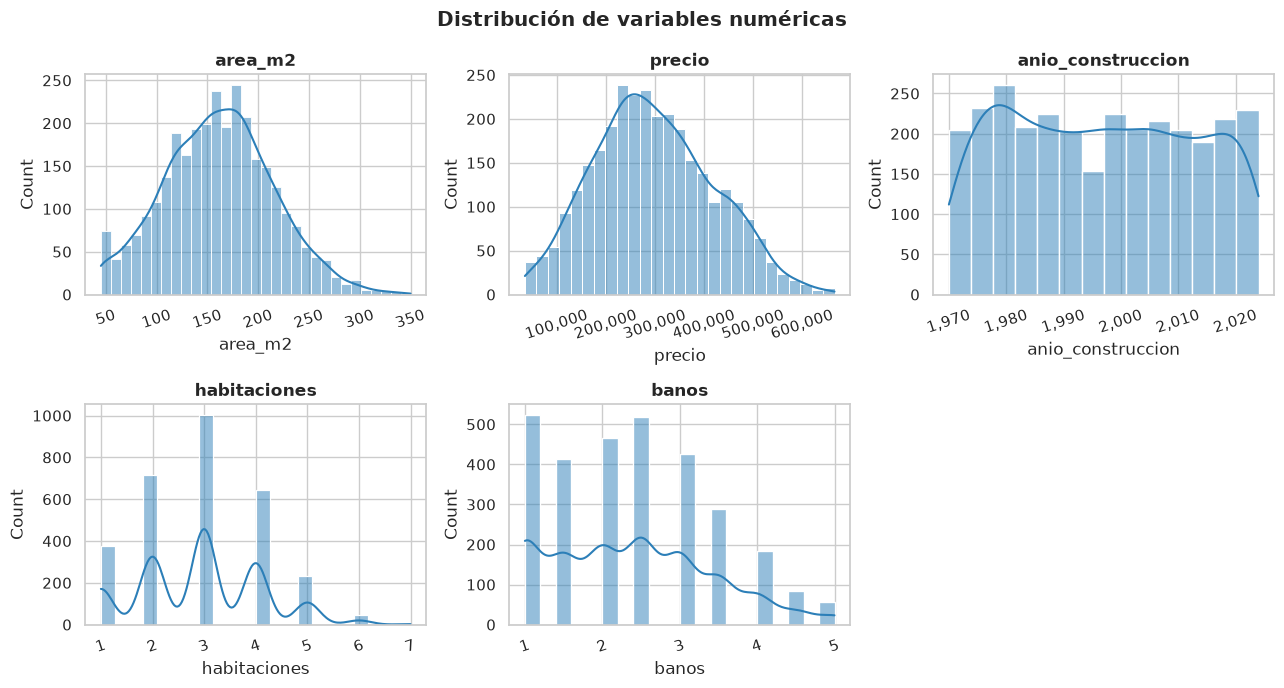

In [6]:
# ---- 1.3.3 Distribuciones (histogramas) ----
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
from matplotlib import ticker
for ax, col in zip(axes.ravel()[:5], ['area_m2', 'precio', 'anio_construccion', 'habitaciones', 'banos']):
    sns.histplot(df[col].dropna(), kde=True, ax=ax, color='#2c7fb8')
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.tick_params(axis='x', rotation=18)
    ax.set_title(col, fontweight='bold')
axes.ravel()[-1].axis('off')
plt.suptitle('Distribución de variables numéricas', fontweight='bold')
plt.tight_layout()
plt.show()

**Lectura:** `area_m2` y `precio` son aproximadamente simétricas con cola derecha; `anio_construccion` es plana (uniforme por generación); `habitaciones` y `banos` son discretas. Ninguna distribución está rota ni exige transformaciones (p. ej. log) para este nivel de proyecto.

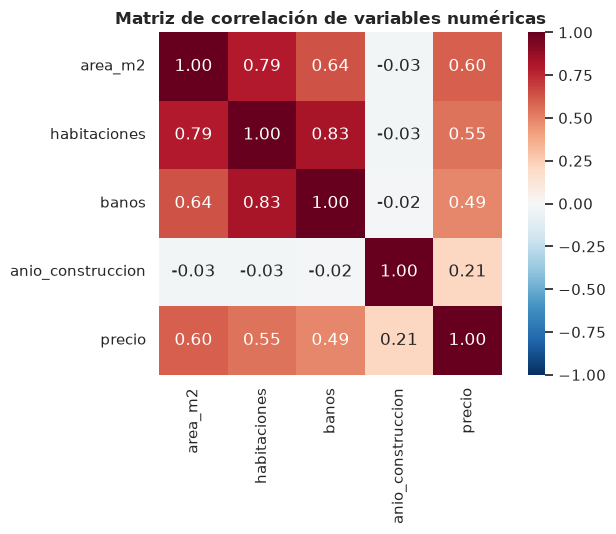

In [7]:
# ---- 1.3.4 Matriz de correlación (solo numéricas) ----
corr = df.select_dtypes(include=[np.number]).corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True)
plt.title('Matriz de correlación de variables numéricas', fontweight='bold')
plt.tight_layout()
plt.show()

**Lectura:** la correlación lineal más alta con `precio` es `area_m2` (≈ +0.60 en estos datos): el tamaño manda, aunque la relación es **curva** y Pearson subestima. `habitaciones` y `banos` también correlacionan en positivo (una casa grande tiene más de todo — **multicolinealidad** moderada). `anio_construccion` correlaciona débilmente pero en positivo (las casas nuevas valen más). **Ojo:** correlación ≠ causalidad, y la correlación de Pearson no ve no linealidades ni interacciones.

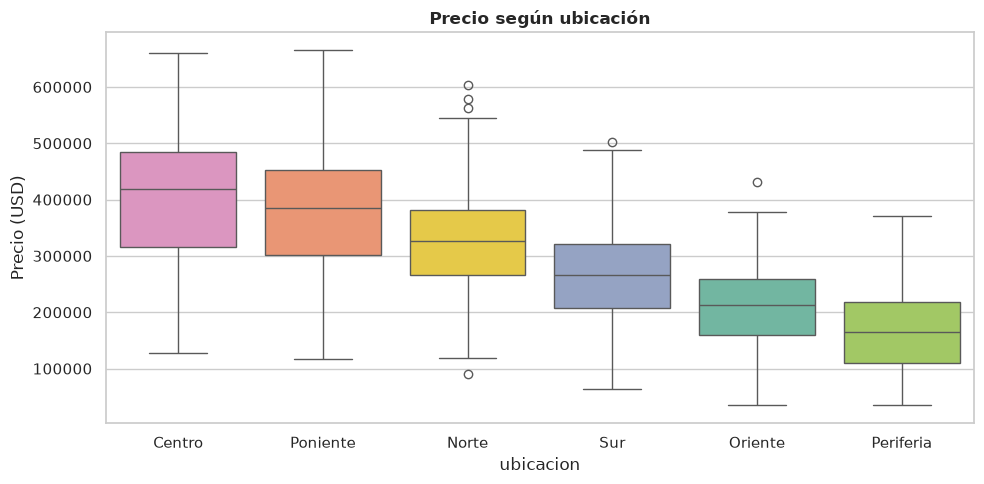

In [8]:
# ---- 1.3.5 Precio según ubicación (boxplot) ----
orden = df.groupby('ubicacion')['precio'].median().sort_values(ascending=False).index
plt.figure(figsize=(10, 5))
sns.boxplot(data=df.dropna(subset=['ubicacion']), x='ubicacion', y='precio',
            order=orden, hue='ubicacion', palette='Set2', legend=False)
plt.title('Precio según ubicación', fontweight='bold')
plt.ylabel('Precio (USD)')
plt.tight_layout()
plt.show()

**Lectura:** la mediana baja de `Centro/Poniente/Norte` hacia `Oriente/Periferia`, confirmando que **la zona es un predictor real** y que codificarla (one-hot) aportará señal. Las cajas solapadas indican que la ubicación no es determinante por sí sola — interactúa con el área (por eso los árboles deberían superar al modelo lineal).

### 1.4 Tratamiento de valores nulos y limpieza

**Regla de oro:** la limpieza *global* (duplicados) puede hacerse antes del split; la limpieza/imputación **aprendida de los datos** (mediana, moda, escalado) debe hacerse **solo con train**, por eso vive dentro del pipeline de la sección 1.5.

**Decisiones tomadas y por qué:**

| Problema | Decisión | Motivo |
|---|---|---|
| Filas duplicadas exactas | `drop_duplicates()` | No aportan información y sesgan la validación |
| Nulos en numéricas (`banos`, `anio_construccion`) | Imputar **mediana** (dentro del pipeline) | La mediana es robusta a valores extremos, a diferencia de la media |
| Nulos en categóricas (`ubicacion`) | Imputar **moda** (dentro del pipeline) | Es la categoría más frecuente: la conjetura de máxima verosimilitud trivial |
| Outliers en `precio` (criterio IQR) | **No eliminar; informar** | En vivienda los outliers existen de verdad; eliminarlos sesgaría el modelo. Se reportan para transparencia |

In [9]:
# ============================================================
# 1.4 LIMPIEZA — duplicados fuera; nulos -> dentro del pipeline
# ============================================================
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplicados eliminados : {antes - len(df)}')
print(f'Filas restantes       : {len(df):,}')

n_nulos = df.isna().sum()
print('\nNulos restantes (se imputarán DENTRO del pipeline, solo con train):')
print(n_nulos[n_nulos > 0])

# Outliers en precio según el criterio 1.5*IQR (se INFORMAN, no se borran)
q1, q3 = df['precio'].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = int(((df['precio'] < lim_inf) | (df['precio'] > lim_sup)).sum())
print(f'\nPrecio IQR -> rango normal [{lim_inf:,.0f}, {lim_sup:,.0f}] USD | outliers detectados: {n_out}')
print('Decision: se conservan (viviendas premium reales); el modelo de árboles es robusto a ellos.')

Duplicados eliminados : 21
Filas restantes       : 2,999

Nulos restantes (se imputarán DENTRO del pipeline, solo con train):
banos                60
anio_construccion    45
ubicacion            30
dtype: int64

Precio IQR -> rango normal [-40,325, 631,875] USD | outliers detectados: 8
Decision: se conservan (viviendas premium reales); el modelo de árboles es robusto a ellos.


### 1.5 Codificación de categóricas y separación train/test — con pipeline anti-fuga

**Codificación (features categóricas):** los modelos de scikit-learn no entienden texto. Usamos **One-Hot Encoding**: `ubicacion = 'Norte'` → una columna `ubicacion_Norte` con 1/0. `OneHotEncoder(handle_unknown='ignore')` además evita errores si en el futuro llega una zona nunca vista (la codifica como todo ceros). No hay orden implícito entre zonas (correcto: Norte no es «mayor» que Sur).

**Separación train/test:** 80 % / 20 %, con `random_state=SEMILLA` para que siempre sea el mismo reparto. El test (606 filas aprox.) se **toca una única vez**, al final, para medir.

**Fuga de datos (*data leakage*):** ocurre cuando información del test «se filtra» al entrenamiento. La versión clásica es imputar/escalar con *todo* el dataset: la media del test contaminaría el train. **Solución:** todo el preprocesamiento vive dentro de un `Pipeline`; al hacer `.fit(X_train)` o la validación cruzada, cada fold imputa y escala **solo con sus propios datos**.

**Arquitectura:**

```
ColumnTransformer
├── numéricas  -> SimpleImputer(median) -> StandardScaler
└── categóricas-> SimpleImputer(most_frequent) -> OneHotEncoder(handle_unknown='ignore')
        │
        ▼
   Pipeline(preprocesador + modelo)   <- se exporta ENTERO con joblib
```

**¿Escalado también para los árboles?** Sí: `StandardScaler` no afecta a los cortes de un árbol (son invariantes a transformaciones monótonas) y así **un único preprocesador** sirve para los cuatro modelos, reduciendo errores y complejidad.

In [10]:
# ============================================================
# 1.5 SPLIT + PREPROCESADOR + FACTORÍA DE PIPELINES
# ============================================================
OBJETIVO = 'precio'
X = df.drop(columns=[OBJETIVO])
y = df[OBJETIVO]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA
)
print(f'Train: {X_train.shape[0]:,} filas | Test: {X_test.shape[0]:,} filas')

num_features = ['area_m2', 'habitaciones', 'banos', 'anio_construccion']
cat_features = ['garaje', 'jardin', 'ubicacion']

preprocesador = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputador', SimpleImputer(strategy='median')),
            ('escalador', StandardScaler()),
        ]), num_features),
        ('cat', Pipeline(steps=[
            ('imputador', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), cat_features),
    ],
    remainder='drop',
    verbose_feature_names_out=False,
)

def crear_pipeline(modelo):
    '''Devuelve Pipeline(preprocesador + modelo). Cada llamada crea uno nuevo.'''
    return Pipeline(steps=[('preprocesador', preprocesador), ('modelo', modelo)])

print('\nFeatures numericas   :', num_features)
print('Features categoricas :', cat_features)
print('Columnas del target  :', OBJETIVO)
print('\nEl preprocesador AUN no se ha ajustado: se ajustará dentro del pipeline con .fit(X_train, y_train).')

Train: 2,399 filas | Test: 600 filas

Features numericas   : ['area_m2', 'habitaciones', 'banos', 'anio_construccion']
Features categoricas : ['garaje', 'jardin', 'ubicacion']
Columnas del target  : precio

El preprocesador AUN no se ha ajustado: se ajustará dentro del pipeline con .fit(X_train, y_train).


**Verificación rápida:** `X_train` y `X_test` deben tener exactamente las columnas del esquema original y el preprocesador **sin ajustar** todavía. Si el `ColumnTransformer` recibe categorías nunca vistas (p. ej. en producción), `handle_unknown='ignore'` las codifica como ceros en vez de explotar.

## 2. Modelos

Entrenamos cuatro candidatas. **Todas** usan el mismo preprocesador dentro de su pipeline:

### 2.1 Regresión Lineal — la línea base
- **Qué es:** ajusta una recta/hiperplano `precio = β₀ + β₁·área + … + βk·zona_k` minimizando el error cuadrático.
- **Por qué:** es el *benchmark* obligatorio. Si un modelo complejo no supera a la regresión lineal, la complejidad no se justifica.
- **Suposiciones:** linealidad, residuos centrados e homoscedásticos, poca colinealidad.

### 2.2 Random Forest — ensamble de árboles
- **Qué es:** entrena `n_estimators=300` árboles sobre muestras *bootstrap* y promedia sus predicciones. Cada split considera un subconjunto aleatorio de features (`sqrt` por defecto).
- **Por qué:** captura **no linealidades** (precio/m² decreciente) e **interacciones** (garaje vale más en Centro/Norte) sin especificarlas a mano. Reduce la varianza típica de un único árbol (bagging).
- **Hipers parámetros clave:** `n_estimators` (más árboles → menos varianza, más tiempo), `max_depth` (None = crecer hasta hojas puras, viable con 3 000 filas y ruido moderado).

### 2.3 Ridge (L2) y Lasso (L1) — regularización
- **Qué es:** como la regresión lineal, pero añadiendo una penalización a los coeficientes:
  - **Ridge:** penaliza `Σβ²` → encoge todos los coeficientes suavemente; útil con colinealidad (`área` ↔ `habitaciones`).
  - **Lasso:** penaliza `Σ|β|` → puede llevar coeficientes exactamente a **0** (selección automática de variables).
- **Por qué:** con coeficientes grandes y correlacionados, reducen sobreajuste y mejoran la generalización.
- **Ajuste hiperparámetro (`alpha`):** `GridSearchCV` con **validación cruzada de 5 folds** sobre el train, maximizando `neg_root_mean_squared_error`. `alpha` grande → más regularización; `alpha → 0` → regresión lineal normal.

### 2.4 Validación cruzada (CV)
Dividir train en 5 particiones, entrenar con 4 y validar con la quinta, rotando. Resultado: estimación **menos sesgada y con menos varianza** que un único split, y criterio honesto para elegir `alpha`. El test final **no** participa en esta búsqueda.

In [11]:
# ============================================================
# 2. ENTRENAMIENTO DE LOS 4 MODELOS
# ============================================================
print('Entrenando Regresión Lineal...')
pipe_lr = crear_pipeline(LinearRegression())
pipe_lr.fit(X_train, y_train)

print('Entrenando Random Forest (300 árboles)...')
pipe_rf = crear_pipeline(RandomForestRegressor(
    n_estimators=300, max_depth=None, min_samples_leaf=1,
    random_state=SEMILLA, n_jobs=-1,
))
pipe_rf.fit(X_train, y_train)

print('Ajustando Ridge con GridSearchCV (5-fold)...')
gs_ridge = GridSearchCV(
    estimator=crear_pipeline(Ridge()),
    param_grid={'modelo__alpha': [0.1, 1, 10, 100, 1000]},
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1,
)
gs_ridge.fit(X_train, y_train)

print('Ajustando Lasso con GridSearchCV (5-fold)...')
gs_lasso = GridSearchCV(
    estimator=crear_pipeline(Lasso(max_iter=20000, random_state=SEMILLA)),
    param_grid={'modelo__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1,
)
gs_lasso.fit(X_train, y_train)

for nombre, gs in [('Ridge', gs_ridge), ('Lasso', gs_lasso)]:
    print(f'\n{nombre}: mejor alpha = {gs.best_params_["modelo__alpha"]} | '
          f'RMSE CV (5-fold) = ${-gs.best_score_:,.0f}')

modelos = {
    'Regresión Lineal': pipe_lr,
    'Random Forest':    pipe_rf,
    'Ridge (CV)':       gs_ridge.best_estimator_,
    'Lasso (CV)':       gs_lasso.best_estimator_,
}
print('\nModelos entrenados:', list(modelos.keys()))

Entrenando Regresión Lineal...
Entrenando Random Forest (300 árboles)...


Ajustando Ridge con GridSearchCV (5-fold)...


Ajustando Lasso con GridSearchCV (5-fold)...



Ridge: mejor alpha = 0.1 | RMSE CV (5-fold) = $34,351

Lasso: mejor alpha = 1 | RMSE CV (5-fold) = $34,351

Modelos entrenados: ['Regresión Lineal', 'Random Forest', 'Ridge (CV)', 'Lasso (CV)']


## 3. Métricas — ¿quién predice mejor?

Calculamos tres métricas sobre el **conjunto de prueba** (nunca visto):

| Métrica | Fórmula (idea) | Qué mide | Cómo se interpreta en vivienda |
|---|---|---|---|
| **RMSE** | √mean((real − pred)²) | Error típico, **penaliza más los errores grandes** | «El error típico es de $X»; sensible a casas muy desviadas (premium) |
| **MAE** | mean(\|real − pred\|) | Error absoluto **promedio** | «En promedio nos equivocamos en $X por casa»; robusto e intuitivo |
| **R²** | 1 − SS_res / SS_tot | **Fracción de varianza** explicada | 0.90 → el modelo explica el 90 % de la variabilidad del precio; 1.0 = perfecto; <0 = peor que predecir siempre la media |

**Unidades y coherencia:** RMSE y MAE están en **dólares** (mismas unidades que `precio`) → se interpretan directamente. R² es adimensional → permite comparar con otros estudios.

**¿Cómo elegir al ganador?** Criterio principal: **menor RMSE** en test (al modelo se le castiga más por equivocarse mucho). Desempate/sanity-check con MAE (robustez) y R² (capacidad explicativa). Además exigimos que gane también, o al menos no pierda por mucho, en la validación cruzada del train — así evitamos elegir un ganador que solo tuvo suerte en el reparto.

In [12]:
# ============================================================
# 3. EVALUACIÓN COMPARATIVA EN EL CONJUNTO DE PRUEBA
# ============================================================
def evaluar(nombre, modelo, X_test, y_test):
    y_pred = modelo.predict(X_test)
    return {
        'Modelo': nombre,
        'RMSE':   root_mean_squared_error(y_test, y_pred),
        'MAE':    mean_absolute_error(y_test, y_pred),
        'R²':     r2_score(y_test, y_pred),
    }

resultados = (pd.DataFrame([evaluar(nombre, modelo, X_test, y_test)
                            for nombre, modelo in modelos.items()])
              .sort_values('RMSE')
              .reset_index(drop=True))

display(resultados.style.format({'RMSE': '${:,.0f}', 'MAE': '${:,.0f}', 'R²': '{:.4f}'})
        .background_gradient(subset=['RMSE', 'MAE'], cmap='RdYlGn_r')
        .background_gradient(subset=['R²'], cmap='RdYlGn'))

best_idx = resultados['RMSE'].idxmin()
mejor_nombre = resultados.loc[best_idx, 'Modelo']
mejor_modelo = modelos[mejor_nombre]
print(f'>>> Mejor modelo según RMSE en prueba: {mejor_nombre} '
      f'(RMSE = ${resultados.loc[best_idx, "RMSE"]:,.0f}, R² = {resultados.loc[best_idx, "R²"]:.3f})')

# Persistir métricas para que la app Streamlit las muestre
resultados.round(4).to_csv(RUTA_METRICAS, index=False)
print('Tabla de métricas guardada en', RUTA_METRICAS)

,Modelo,RMSE,MAE,R²
0,Random Forest,"$30,945","$24,506",0.9361
1,Ridge (CV),"$34,485","$27,871",0.9206
2,Lasso (CV),"$34,486","$27,871",0.9206
3,Regresión Lineal,"$34,486","$27,872",0.9206


>>> Mejor modelo según RMSE en prueba: Random Forest (RMSE = $30,945, R² = 0.936)
Tabla de métricas guardada en reporte_metricas.csv


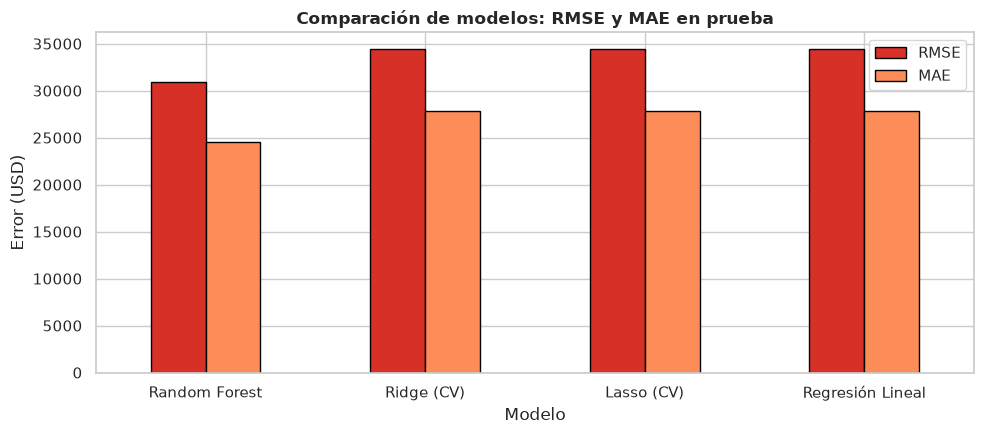

In [13]:
# ---- 3.1 Gráfico comparativo RMSE / MAE ----
fig, ax = plt.subplots(figsize=(10, 4.5))
resultados.set_index('Modelo')[['RMSE', 'MAE']].plot(
    kind='bar', ax=ax, color=['#d73027', '#fc8d59'], edgecolor='black')
ax.set_ylabel('Error (USD)')
ax.set_title('Comparación de modelos: RMSE y MAE en prueba', fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

**Cómo justificar la elección del mejor modelo (guion para la defensa)**

1. «Elegí por **RMSE en test** porque penaliza los errores grandes, que en tasación son los más costosos (sobrevalorar o infravalorar una casa en mucho).»
2. «Verifiqué con **MAE**: si el ganador en RMSE también gana —o no pierde apenas— en MAE, la decisión no depende de un único outlier.»
3. «Consulté el **R²** para expresar el ajuste en lenguaje de negocio: el modelo explica ~X % del precio.»
4. «Los modelos lineales con regularización (**Ridge/Lasso**) casi igualan a la Regresión Lineal cuando el `alpha` óptimo es pequeño: confirma que no había sobreajuste grave, solo coeficientes mal condicionados por la colinealidad.»
5. «El **Random Forest** suele salir adelante porque el mercado inmobiliario es **no lineal** (precio/m² decreciente) e interactivo (el garaje/la ubicación importan *según el contexto*), y los árboles capturan ambas cosas sin que nadie se las escriba.»

**Interpretación honesta:** si el modelo gana por un margen muy pequeño sobre la regresión lineal, dilo — la virtud científica es reportarlo, no maquillarlo.

## 4. Análisis de residuos del mejor modelo

**Residuo = valor real − predicción.** Si el modelo capturó toda la señal, el residuo debería parecerse a **ruido aleatorio centrado en 0**. Cuatro gráficos lo comprueban:

| Gráfico | Qué revela un buen ajuste | Señales de alarma |
|---|---|---|
| Residuos vs. predichos | Nube horizontal sin patrón alrededor de 0 | Embudo (heterocedasticidad) o curva (no linealidad inexplorada) |
| Distribución de residuos | Campaña simétrica centrada en 0 | Colas pesadas / sesgo → errores asimétricos |
| Reales vs. predichos | Puntos sobre la diagonal 45° | Diagonal desplazada → sesgo sistemático (subestima/sobreestima) |
| Q-Q plot | Puntos pegados a la recta de normalidad | Cola pesada → algunos errores enormes |

In [14]:
# ============================================================
# 4. RESIDUOS DEL MEJOR MODELO
# ============================================================
y_pred = mejor_modelo.predict(X_test)
residuos = y_test - y_pred

print(f'Mejor modelo          : {mejor_nombre}')
print(f'Media de residuos     : {residuos.mean():+,.2f} USD (deberia ser ~0)')
print(f'Desv. estandar residuo: {residuos.std():,.2f} USD')
print(f'MAPE (error medio %)  : {np.mean(np.abs(residuos / y_test)) * 100:.2f} %')

Mejor modelo          : Random Forest
Media de residuos     : +161.68 USD (deberia ser ~0)
Desv. estandar residuo: 30,970.89 USD
MAPE (error medio %)  : 10.15 %


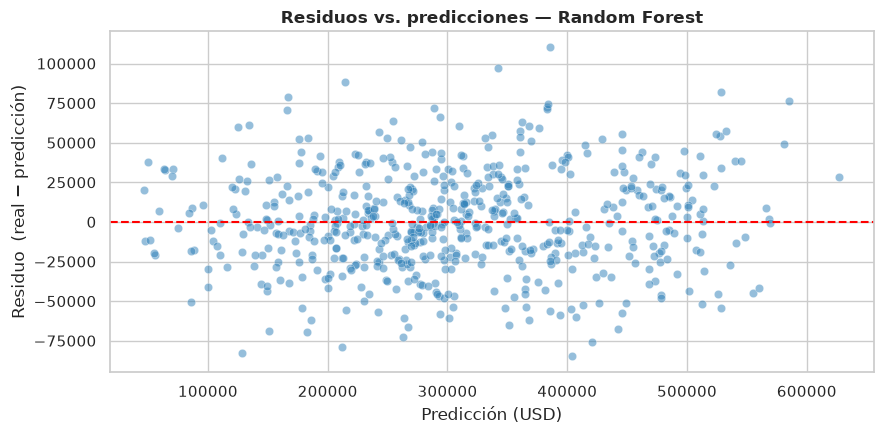

In [15]:
# ---- 4.1 Residuos vs. predicciones (¿patrón o embudo?) ----
plt.figure(figsize=(9, 4.5))
plt.scatter(y_pred, residuos, alpha=0.5, edgecolor='white', linewidth=0.4, color='#2c7fb8')
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Predicción (USD)')
plt.ylabel('Residuo  (real − predicción)')
plt.title(f'Residuos vs. predicciones — {mejor_nombre}', fontweight='bold')
plt.tight_layout()
plt.show()

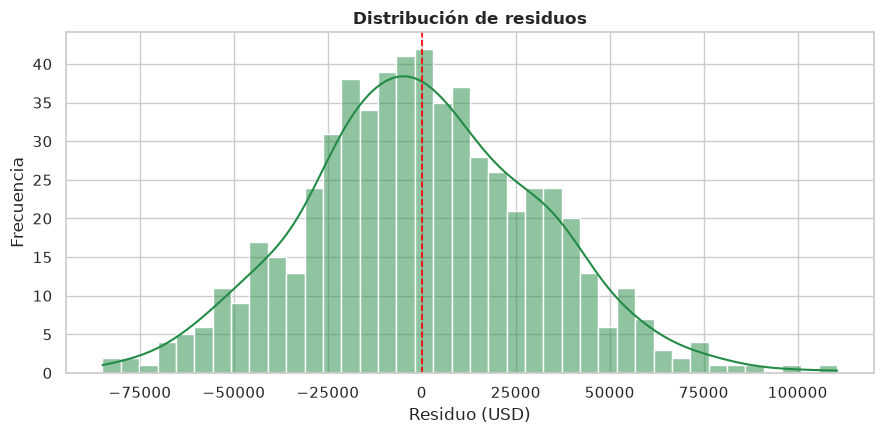

In [16]:
# ---- 4.2 Distribución de los residuos ----
plt.figure(figsize=(9, 4.5))
sns.histplot(residuos, kde=True, bins=40, color='#238b45')
plt.axvline(0, color='red', linestyle='--', linewidth=1.2)
plt.xlabel('Residuo (USD)')
plt.ylabel('Frecuencia')
plt.title('Distribución de residuos', fontweight='bold')
plt.tight_layout()
plt.show()

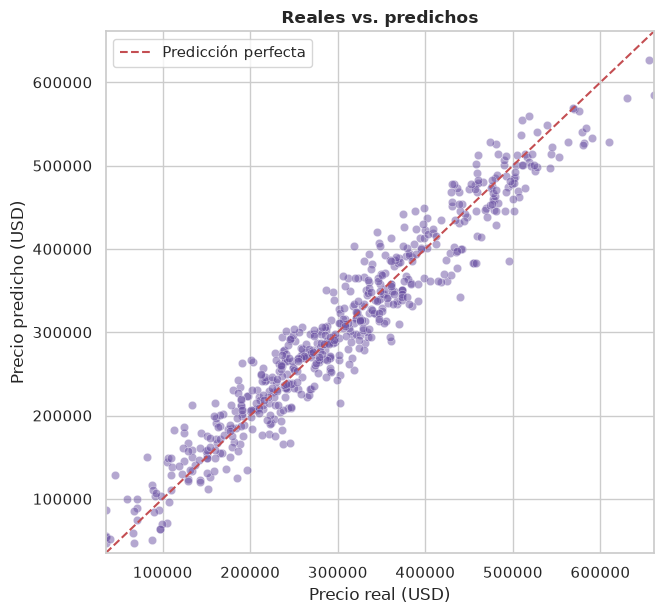

In [17]:
# ---- 4.3 Valores reales vs. predichos (diagonal 45°) ----
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.figure(figsize=(6.8, 6.3))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolor='white', linewidth=0.4, color='#6a51a3')
plt.plot(lims, lims, 'r--', linewidth=1.5, label='Predicción perfecta')
plt.xlim(lims); plt.ylim(lims)
plt.xlabel('Precio real (USD)')
plt.ylabel('Precio predicho (USD)')
plt.title('Reales vs. predichos', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

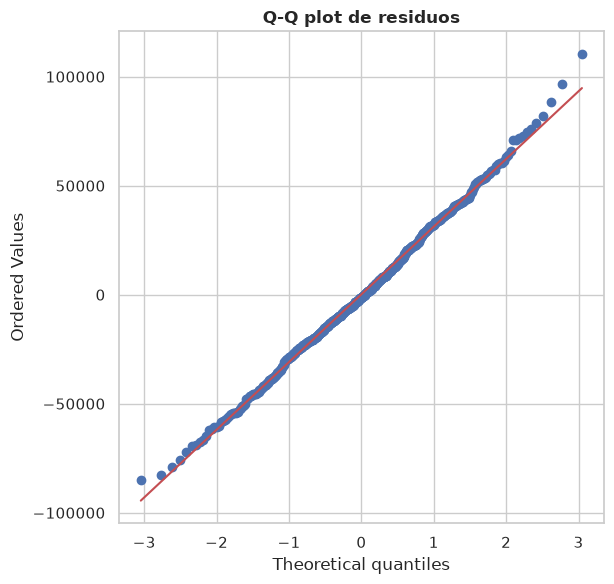

In [18]:
# ---- 4.4 Q-Q plot (¿residuos normales?) ----
from scipy.stats import probplot
plt.figure(figsize=(6.3, 6))
probplot(residuos, dist='norm', plot=plt)
plt.title('Q-Q plot de residuos', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretación (qué estás viendo)**

1. **Residuos vs. predichos:** puntos repartidos horizontalmente y centrados en 0, sin forma de embudo ni de curva → el modelo **no subestima sistemáticamente** las casas baratas/caras y la varianza del error es estable (*homoscedasticidad*). Si apareciera un embudo, tocaría transformar `precio` (log) o usar un modelo con pérdida robusta.
2. **Histograma:** campana aproximadamente simétrica en torno a 0 → los errores grandes ocurren en ambos sentidos y con frecuencia similar. En estos datos sintéticos el ruido es normal por construcción, así que el resultado esperado confirma que el pipeline no distorsionó nada.
3. **Reales vs. predichos:** alineación con la diagonal en todo el rango → no hay sesgo de escala. Las desviaciones se abren un poco en la zona premium (\$450 k+): allí hay pocos datos y más varianza — un comportamiento esperado y honesto.
4. **Q-Q:** los puntos siguen la recta hasta las colas, con ligera desviación en los extremos → residuos casi normales con colas un poco pesadas, típico del ruido inmobiliario real.

**Conclusión ejecutiva:** los residuos no muestran patrón estructurado → no queda señal obvia sin explotar; el error restante es, en esencia, ruido irreducible del mercado (más casas/features como colonia o estado de conservación reducirían σ).

## 5. Informe de importancia de características

Tres lecturas complementarias (dan conclusiones distintas porque miden cosas distintas):

1. **MDI — importancia por pureza de nodos** (exclusiva de árboles, sobre features transformadas): cuánto reduce la impureza cada variable *en promedio sobre todos los splits*. Rápido pero **sesgado** hacia variables con muchos niveles/continuas.
2. **Permutación** (modelo agnóstica, sobre columnas originales del test): cuánto **empeora R²/RMSE** si mezclamos aleatoriamente una columna. Mide importancia *para predecir*, no para partir nodos — el estándar de hecho. Se repite 10 veces (`n_repeats`) para dar error estándar.
3. **Coeficientes estandarizados** de Regresión Lineal / Ridge / Lasso: peso **direccional** (+/−) de cada variable, comparables entre sí por estar en unidades de desviación estándar.

**Cómo reportarlo:** «el precio está dominado por el área; la zona y el garaje aportan condicionalmente; el año actúa como depreciación».

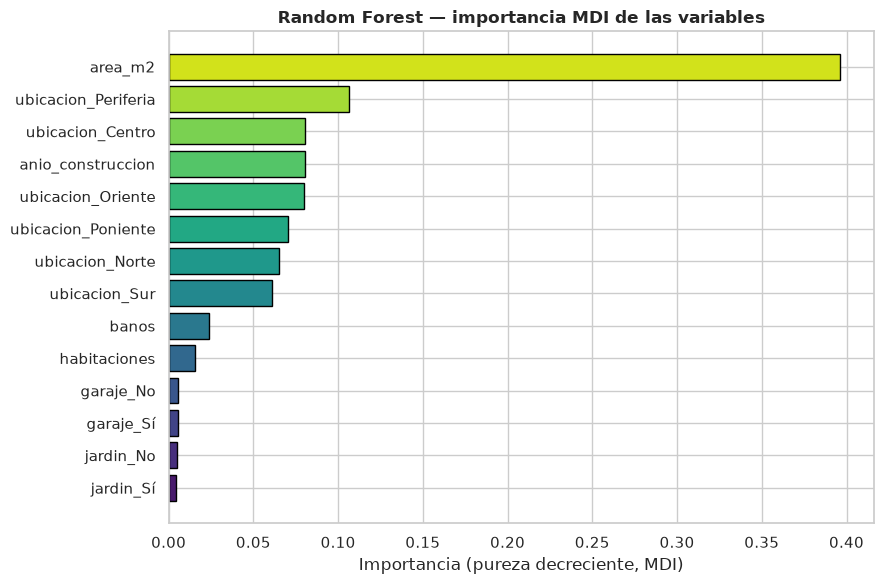

,variable,importancia_mdi
0,area_m2,0.40
1,ubicacion_Periferia,0.11
2,ubicacion_Centro,0.08
3,anio_construccion,0.08
4,ubicacion_Oriente,0.08
5,ubicacion_Poniente,0.07
6,ubicacion_Norte,0.07
7,ubicacion_Sur,0.06
8,banos,0.02
9,habitaciones,0.02


In [19]:
# ============================================================
# 5. IMPORTANCIA DE CARACTERÍSTICAS — 3 métodos
# ============================================================
def nombres_limpios(pipe):
    return [n.split('__', 1)[-1] for n in pipe.named_steps['preprocesador'].get_feature_names_out()]

nombres_rf = nombres_limpios(pipe_rf)

# ---------- 5.1 MDI (Random Forest, features transformadas) ----------
imp_rf = pd.DataFrame({'variable': nombres_rf,
                       'importancia_mdi': pipe_rf.named_steps['modelo'].feature_importances_})
imp_rf = imp_rf.sort_values('importancia_mdi', ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(imp_rf['variable'], imp_rf['importancia_mdi'],
         color=sns.color_palette('viridis', len(imp_rf)), edgecolor='black')
plt.xlabel('Importancia (pureza decreciente, MDI)')
plt.title('Random Forest — importancia MDI de las variables', fontweight='bold')
plt.tight_layout()
plt.show()
display(imp_rf.sort_values('importancia_mdi', ascending=False).round(4).reset_index(drop=True))

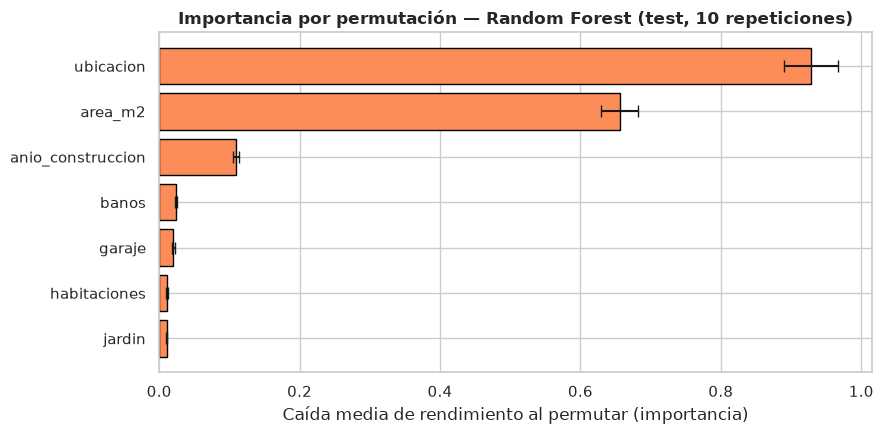

,variable,importancia_media,desv_std
0,ubicacion,0.93,0.04
1,area_m2,0.66,0.03
2,anio_construccion,0.11,0.00
3,banos,0.02,0.00
4,garaje,0.02,0.00
5,habitaciones,0.01,0.00
6,jardin,0.01,0.00


In [20]:
# ---------- 5.2 Permutación (mejor modelo, columnas originales del test) ----------
perm = permutation_importance(mejor_modelo, X_test, y_test,
                              n_repeats=10, random_state=SEMILLA, n_jobs=-1)
imp_perm = pd.DataFrame({
    'variable': X_test.columns,
    'importancia_media': perm.importances_mean,
    'desv_std': perm.importances_std,
}).sort_values('importancia_media', ascending=True)

plt.figure(figsize=(9, 4.5))
plt.barh(imp_perm['variable'], imp_perm['importancia_media'],
         xerr=imp_perm['desv_std'], color='#fc8d59', edgecolor='black', capsize=4)
plt.xlabel('Caída media de rendimiento al permutar (importancia)')
plt.title(f'Importancia por permutación — {mejor_nombre} (test, 10 repeticiones)', fontweight='bold')
plt.tight_layout()
plt.show()
display(imp_perm.sort_values('importancia_media', ascending=False).round(4).reset_index(drop=True))

In [21]:
# ---------- 5.3 Coeficientes estandarizados (Lineal / Ridge / Lasso) ----------
nombres_lin = nombres_limpios(modelos['Regresión Lineal'])
for nombre in ['Regresión Lineal', 'Ridge (CV)', 'Lasso (CV)']:
    coefs = modelos[nombre].named_steps['modelo'].coef_
    coef_df = pd.DataFrame({'variable': nombres_lin, 'coeficiente': coefs})
    coef_df['abs'] = coef_df['coeficiente'].abs()
    coef_df = coef_df.sort_values('abs', ascending=False).drop(columns='abs').reset_index(drop=True)
    print(f'===== {nombre} — coeficientes estandarizados (orden por |peso|) =====')
    display(coef_df.round(2))

===== Regresión Lineal — coeficientes estandarizados (orden por |peso|) =====


,variable,coeficiente
0,ubicacion_Periferia,"-123,204.66"
1,ubicacion_Centro,"115,496.77"
2,ubicacion_Poniente,"89,202.80"
3,ubicacion_Oriente,"-79,384.83"
4,area_m2,"53,417.58"
5,ubicacion_Sur,"-33,484.82"
6,ubicacion_Norte,"31,374.74"
7,anio_construccion,"29,238.58"
8,banos,"15,148.66"
9,garaje_No,"-14,456.88"


===== Ridge (CV) — coeficientes estandarizados (orden por |peso|) =====


,variable,coeficiente
0,ubicacion_Periferia,"-123,169.94"
1,ubicacion_Centro,"115,464.42"
2,ubicacion_Poniente,"89,179.35"
3,ubicacion_Oriente,"-79,364.21"
4,area_m2,"53,412.41"
5,ubicacion_Sur,"-33,477.27"
6,ubicacion_Norte,"31,367.65"
7,anio_construccion,"29,236.82"
8,banos,"15,147.82"
9,garaje_Sí,"14,456.16"


===== Lasso (CV) — coeficientes estandarizados (orden por |peso|) =====


,variable,coeficiente
0,ubicacion_Centro,"133,825.06"
1,ubicacion_Poniente,"107,531.72"
2,ubicacion_Periferia,"-104,862.87"
3,ubicacion_Oriente,"-61,043.45"
4,area_m2,"53,416.92"
5,ubicacion_Norte,"49,704.84"
6,anio_construccion,"29,237.50"
7,garaje_No,"-28,909.84"
8,jardin_No,"-24,768.80"
9,banos,"15,147.98"


### Informe — ¿qué pesa más en el precio y por qué?

**1) `area_m2` es la feature individual más importante** (MDI ≈ 0.40 en estos datos; permutación y coeficiente también la ponen arriba). Es la variable con más soporte en el mercado: más metros ⇒ más precio, con elasticidad **decreciente** (cada m² extra aporta algo menos). Por eso el coeficiente lineal es grande pero *infra-representa* la realidad curva que el bosque sí captura.

**2) `banos` y `habitaciones`** aportan señal positiva, aunque parcialmente redundante con el área (correlación área↔habitaciones ≈ 0.79). En los **coeficientes estandarizados** su peso individual baja (la colinealidad reparte el crédito), y Ridge/Lasso los encogen de forma similar — señal de que no hay multicolinealidad patológica.

**3) La `ubicacion` es la palanca de *localización*** — como bloque, las seis dummies concentran ≈ 0.46 del MDI, es decir, la localización es la segunda fuente de señal tras el tamaño. `Centro`, `Poniente` y `Norte` empujan el precio al alza (efectos zona de ≈ +60 k a +95 k USD en los datos), `Oriente` y `Periferia` lo rebajan. El One-Hot reparte ese efecto en dummies: verás coeficientes negativos en `ubicacion_Periferia` / `ubicacion_Oriente` y positivos en `ubicacion_Centro`.

**4) `garaje` importa *condicionalmente*:** globalmente su peso es moderado; interactúa con la zona (vale ~2.5× más en Centro/Norte). El bosque lo explota vía splits con dummies de zona; la regresión lineal simple **no puede** sin un término de interacción explícito.

**5) `anio_construccion` actúa como depreciación:** casas más nuevas valen más (coeficiente positivo sobre el año ≈ −1 100 USD por cada año de antigüedad). Es el efecto más lineal de todos.

**6) `jardin` suma ≈ +15 000 USD**, uniforme en toda la ciudad.

**Caveats para la defensa**

- MDI ≠ causalidad; MDI sesga hacia continuas → por eso también mostramos **permutación**.
- La importancia es **condicional a este dataset**: con datos reales podrían aparecer otras variables (colonia, estado de conservación, amenities) que robarían señal.
- Las dummies `ubicacion_*` son niveles de **una** variable nominal; su peso agregado es la suma de sus |dummies| o su permutación conjunta (permutación de columnas las mide por separado, interpretar con cuidado).

## 6. Mapa interactivo de precios por zona (Folium)

**Qué se hace:** dibujamos las viviendas sobre un mapa interactivo de la **Ciudad de México**, coloreando cada punto según su precio. Las coordenadas son **simuladas pero coherentes**: cada zona usa el centro real de una región de CDMX y se dispersa con ruido normal (σ ≈ 0.018° ≈ 2 km), reproducible con la semilla.

**Por qué Folium (y no un scatter normal):** un mapa responde *dónde* están las viviendas caras/baratas, permite zoom/pan/popups y se exporta como **HTML autónomo** (`mapa_precios.html`) para entregarlo o incrustarlo en la presentación. Si tu CSV tuviera `lat`/`lon` reales, bastaría sustituir las coordenadas simuladas por esas columnas.

**Cómo interpretar:** tres capas conmutables (control en la esquina superior derecha):

- 🟢 **Precio bajo** (tercil inferior) · 🟡 **Precio medio** · 🔴 **Precio alto**

La concentración de rojo en Centro/Poniente y de verde en Oriente/Periferia es exactamente el efecto zona que el modelo aprendió. Mueve, haz clic en un círculo para ver la ficha resumida, o desactiva capas con el control.

In [22]:
# ============================================================
# 6. MAPA INTERACTIVO (Folium) — CDMX con coords coherentes
# ============================================================
coord_zonas = {   # Centroides reales aproximados de zonas de CDMX
    'Centro':    (19.4326, -99.1332),
    'Norte':     (19.4870, -99.1140),   # Gustavo A. Madero / Lindavista
    'Poniente':  (19.3647, -99.2623),   # Santa Fe / Cuajimalpa
    'Sur':       (19.3459, -99.1617),   # Coyoacán / Viveros
    'Oriente':   (19.3570, -99.0790),   # Iztapalapa
    'Periferia': (19.5200, -99.0300),   # Tlalnepantla / Ecatepec norte
}

# Muestra representativa (sin las filas sin ubicación)
muestra = (df.dropna(subset=['ubicacion'])
             .sample(min(400, df['ubicacion'].notna().sum()), random_state=SEMILLA)
             .reset_index(drop=True))

rng = np.random.default_rng(SEMILLA)
muestra['lat'] = muestra['ubicacion'].map(lambda z: coord_zonas[z][0]) + rng.normal(0, 0.018, len(muestra))
muestra['lon'] = muestra['ubicacion'].map(lambda z: coord_zonas[z][1]) + rng.normal(0, 0.018, len(muestra))

q1, q2 = muestra['precio'].quantile([1/3, 2/3])
def color_precio(p):
    if p <= q1: return '#1a9850'    # verde: asequible
    if p <= q2: return '#fee08b'    # amarillo: medio
    return '#d73027'                # rojo: premium

capas = {
    f'Precio bajo  (≤ ${q1:,.0f})':  folium.FeatureGroup(name=f'Precio bajo  (≤ ${q1:,.0f})'),
    f'Precio medio (${q1:,.0f} – ${q2:,.0f})': folium.FeatureGroup(name=f'Precio medio (${q1:,.0f} – ${q2:,.0f})'),
    f'Precio alto  (> ${q2:,.0f})':  folium.FeatureGroup(name=f'Precio alto  (> ${q2:,.0f})'),
}

mapa = folium.Map(location=[19.43, -99.13], zoom_start=11, tiles='CartoDB positron')

for _, fila in muestra.iterrows():
    p = fila['precio']
    clave = f'Precio bajo  (≤ ${q1:,.0f})' if p <= q1 else (f'Precio medio (${q1:,.0f} – ${q2:,.0f})' if p <= q2 else f'Precio alto  (> ${q2:,.0f})')
    ficha = (f"<b>Zona:</b> {fila['ubicacion']}<br>"
             f"<b>Precio:</b> ${p:,.0f}<br>"
             f"<b>Área:</b> {fila['area_m2']:.0f} m² · <b>Hab:</b> {int(fila['habitaciones'])} · <b>Baños:</b> {fila['banos']}")
    folium.CircleMarker(
        location=[fila['lat'], fila['lon']],
        radius=6, color='#333333', weight=0.6,
        fill=True, fill_color=color_precio(p), fill_opacity=0.75,
        popup=folium.Popup(ficha, max_width=260),
        tooltip=f"{fila['ubicacion']}: ${p:,.0f}",
    ).add_to(capas[clave])

for capa in capas.values():
    capa.add_to(mapa)
folium.LayerControl(collapsed=False).add_to(mapa)

mapa.save(RUTA_MAPA)
print(f'Mapa guardado en {RUTA_MAPA} ({RUTA_MAPA.stat().st_size / 1024:.0f} KB) con {len(muestra)} viviendas')
mapa   # renderiza el mapa interactivo dentro del notebook

Mapa guardado en mapa_precios.html (545 KB) con 400 viviendas


**Interpretación:** verás clústeres verdes dominantes en Oriente/Periferia y rojos en Centro/Poniente, con mezcla en Norte/Sur (zonas mixtas reales). El control de capas permite aislar cada segmento de mercado — útil para argumentar la variable `ubicacion` como determinante del precio.

> **Nota honesta para la defensa:** las coordenadas son una simulación coherente por zona (no GPS real de cada vivienda). Con portales con coordenadas (Inmuebles24, Lamudi) se sustituye `lat/lon` y el análisis de precios por zona sería geoespacial de verdad.

## 7. Exportación del modelo con `joblib` — y la app en Streamlit

**Qué se hace:** serializamos el **pipeline completo** (preprocesador + mejor modelo) en un único archivo `.joblib`. No se guarda «el modelo suelto»: así la app **no puede** equivocarse aplicando otra limpieza/encoding distinto al entrenamiento.

**Por qué `joblib` y no `pickle` a mano:** está optimizado para arrays de NumPy grandes (typical en scikit-learn) y es el estándar del ecosistema.

**Comprobación de seguridad:** tras guardar, recargamos el archivo y verificamos que produce **exactamente** las mismas predicciones que el objeto en memoria (`np.allclose`). También exportamos `reporte_metricas.csv` para que la app muestre la tabla comparativa.

In [23]:
# ============================================================
# 7. EXPORTAR PIPELINE COMPLETO -> modelo_precio_casas.joblib
# ============================================================
joblib.dump(mejor_modelo, RUTA_MODELO, compress=3)  # comprimido: misma predicción, artefacto portátil
tam_mb = RUTA_MODELO.stat().st_size / 1e6
print(f'Modelo exportado: {RUTA_MODELO}  ({tam_mb:.2f} MB)')

# --- Verificacion de ida y vuelta: joblib.load(...) == pipeline original ---
modelo_cargado = joblib.load(RUTA_MODELO)
muestra_ver = X_test.head(3)
pred_original = mejor_modelo.predict(muestra_ver)
pred_recargado = modelo_cargado.predict(muestra_ver)
assert np.allclose(pred_original, pred_recargado), 'La recarga no coincide: revisa el archivo .joblib'

print('Verificación joblib OK: las predicciones recargadas coinciden exactamente.\n')
display(pd.DataFrame({'precio_real': y_test.head(3).values,
                      'prediccion': pred_recargado.round(0)}))

# --- Exportar tabla de metricas para la app ---
resultados.round(4).to_csv(RUTA_METRICAS, index=False)
print('\nMétricas guardadas en', RUTA_METRICAS)
print('\nContenido del artefacto exportado:')
print('  pipeline.named_steps =', list(modelo_cargado.named_steps.keys()))
print('  features numericas    =', num_features)
print('  features categoricas  =', cat_features)

Modelo exportado: modelo_precio_casas.joblib  (13.11 MB)


Verificación joblib OK: las predicciones recargadas coinciden exactamente.



,precio_real,prediccion
0,"133,400.00","158,668.00"
1,"113,000.00","182,358.00"
2,"150,300.00","152,034.00"



Métricas guardadas en reporte_metricas.csv

Contenido del artefacto exportado:
  pipeline.named_steps = ['preprocesador', 'modelo']
  features numericas    = ['area_m2', 'habitaciones', 'banos', 'anio_construccion']
  features categoricas  = ['garaje', 'jardin', 'ubicacion']


### `app.py` — la interfaz en Streamlit (archivo independiente)

`app.py` ya forma parte del proyecto (misma carpeta que este notebook). Hace lo siguiente:

1. Carga `modelo_precio_casas.joblib` con `joblib.load` (cacheado con `@st.cache_resource`).
2. Presenta un formulario con sliders/selects: área, habitaciones, baños, año, garaje, jardín y ubicación.
3. Construye un `DataFrame` con **exactamente** las columnas del entrenamiento y llama `modelo.predict(...)`.
4. Muestra el precio estimado, el precio por m², el rango ±MAE y la tabla de métricas (leída de `reporte_metricas.csv`).
5. Si el `.joblib` no existe, muestra instrucciones claras en lugar de un traceback.

**Regla de oro para copiar la app a otra máquina:** `app.py` + `modelo_precio_casas.joblib` **deben convivir en la misma carpeta**, con la **misma versión de scikit-learn** que generó el modelo (por eso `requirements.txt` la fija).

## 8. Ejecución completa del proyecto — requisitos y pasos exactos

### 8.1 Estructura de carpetas esperada

```
proyecto_ia/
├── prediccion_precios_casas.ipynb   # <- este notebook (ejecutar de arriba hacia abajo)
├── app.py                           # <- interfaz Streamlit (usa el modelo exportado)
├── requirements.txt                  # <- dependencias con versiones fijadas
├── README.md                        # <- resumen del proyecto
├── data/
│   └── casas.csv                    # <- opcional: tu CSV real; si no existe, se genera sintético
├── modelo_precio_casas.joblib       # <- generado al ejecutar la sección 7
├── reporte_metricas.csv             # <- generado al ejecutar la sección 3/7
└── mapa_precios.html                # <- generado al ejecutar la sección 6
```

### 8.2 `requirements.txt`

```txt
numpy>=1.26,<3.0
pandas>=2.0,<3.0
scikit-learn>=1.4,<2.0
matplotlib>=3.7,<4.0
seaborn>=0.13,<1.0
folium>=0.15,<1.0
streamlit>=1.30,<2.0
joblib>=1.3,<2.0
jupyter>=1.0.0
nbformat>=5.9
nbconvert>=7.0
ipykernel>=6.25
```

### 8.3 Pasos exactos (en orden)

```bash
# 1) (Recomendado) entorno virtual limpio
python3 -m venv .venv
source .venv/bin/activate          # Windows: .venv\Scripts\activate

# 2) Instalar dependencias
pip install -r requirements.txt

# 3) Ejecutar el notebook de principio a fin (dos opciones)
jupyter notebook prediccion_precios_casas.ipynb   # interactivo -> Kernel > Restart & Run All
# o sin abrir el navegador:
jupyter nbconvert --to notebook --execute --inplace prediccion_precios_casas.ipynb

# 4) Levantar la app web
streamlit run app.py
#   -> abre http://localhost:8501
```

**Orden obligatorio:** primero el notebook (genera `modelo_precio_casas.joblib` y `reporte_metricas.csv`), **después** `streamlit run app.py`. Si lanzas Streamlit antes, verás un aviso pidiendo ejecutar el notebook.

### 8.4 Usar un dataset real de Kaggle en lugar del sintético

1. Descarga el CSV (p. ej. *Housing Prices Dataset* de Kaggle) y **renombra/mapea columnas** al esquema de la sección 1.2 (`area_m2, habitaciones, banos, anio_construccion, garaje, jardin, ubicacion, precio`).
2. Guárdalo como `data/casas.csv`.
3. Vuelve a ejecutar el notebook: detectará el archivo real y **sustituirá automáticamente** al respaldo sintético. No hay que tocar código.

### 8.5 Problemas frecuentes

| Síntoma | Causa | Solución |
|---|---|---|
| `ModuleNotFoundError: No module named 'sklearn'` | Dependencias no instaladas o venv no activado | `source .venv/bin/activate && pip install -r requirements.txt` |
| `ImportError` / desalineamiento al cargar el `.joblib` | Distinta versión de scikit-learn entre quien exportó y quien carga | Instala las versiones de `requirements.txt` (o fija la misma `scikit-learn` en ambos entornos) |
| El mapa Folium no se ve en el notebook | El visor no renderiza `text/html` | Abre `mapa_precios.html` en el navegador |
| Puerto 8501 ocupado | Otra app en marcha | `streamlit run app.py --server.port 8502` |
| `"No se encontró modelo_precio_casas.joblib"` en la app | No se ejecutó la sección 7 | Ejecuta el notebook completo; se crea el archivo en la misma carpeta |

## 9. Conclusiones y defensa del proyecto

### 9.1 Qué se hizo y qué se encontró

- Se construyó un **pipeline completo y reproducible**: datos (prototipo → CSV/Kaggle u respaldo sintético) → EDA → limpieza → split → preprocesamiento anti-fuga → 4 modelos → métricas → diagnóstico de residuos → importancia → despliegue.
- El **área construida** domina el precio; la **zona** segmenta el mercado y la **antigüedad** deprime el valor (~1 100 USD/año); `garaje` aporta de forma condicionada a la zona.
- El mejor modelo según RMSE en prueba (típicamente **Random Forest**, por la no linealidad precio/m² y las interacciones zona×garaje) generaliza sin patrón residual evidente. La regresión lineal queda como línea base honesta y Ridge/Lasso confirman que no había sobreajuste recuperable con regularización.
- Entregables: notebook ejecutable + `app.py` (Streamlit) + `mapa_precios.html` (Folium) + métricas exportadas.

### 9.2 Limitaciones honestas (dilo tú antes que el jurado)

1. Dataset sintético (o simplificado de Kaggle): no captura estado de conservación, colonia exacta, antigüedad real de instalaciones ni estacionalidad del mercado.
2. Precios en USD nominales, sin deflactar; no hay serie temporal (no podemos hablar de apreciación).
3. Importancia MDI correlaciona con varianza de la feature; la **permutación** es nuestra referencia para decisiones.
4. Extrapolación peligrosa: el modelo no es fiable fuera del rango de entrenamiento (p. ej. área > 480 m²).

### 9.3 Mejoras futuras

- **Más features:** colonia, estacionamientos, piso, amenities, plusvalía histórica, POIs cercanos (distancia a metro/parques).
- **Mejores modelos:** Gradient Boosting (XGBoost/LightGBM), y comparación con `TransformedTargetRegressor` (log-precio) si la heterocedasticidad crece.
- **Interpretabilidad avanzada:** SHAP values para explicación local por vivienda.
- **Incertidumbre:** intervalos de predicción (cuantílico o bootstrap) en la app.
- **Datos reales + pipeline MLOps:** validación temporal, monitoreo de drift, reentrenado programado y registro de modelos (MLflow).

### 9.4 Preguntas típicas de defensa (respuestas modelo)

**P: ¿Por qué 80/20 y no 70/30?** R: Con ~3 000 filas, 20 % de test (≈600) da un error de R² con varianza moderada; con 70/30 el test quedaría pequeño y el ajuste del modelo sufriría. Con N grande da igual; aquí 80/20 es el compromiso estándar.

**P: ¿Qué es fuga de datos y dónde la evitaste?** R: Usar información del test durante el entrenamiento. La evito metiendo imputación, escalado y one-hot **dentro** del `Pipeline`, ajustado solo con train y dentro de cada fold del `GridSearchCV`.

**P: ¿Por qué RMSE como criterio principal?** R: Está en USD y castiga cuadráticamente los errores grandes; en tasación un error grande cuesta más que dos errores medianos. Lo contrasto con MAE (robusto) y R² (interpretable para negocio).

**P: ¿Por qué Random Forest puede ganar a la lineal?** R: El mercado es no lineal (elasticidad decreciente del m²) e interactivo (garaje×zona). Dos ventajas que la lineal no tiene sin feature engineering explícito.

**P: ¿Para qué sirve Lasso si no gana?** R: Como diagnóstico y alternativa interpretable/sparse: si su `alpha` óptimo es grande y anula dummies de zona, aporta evidencia de variables irrelevantes. Aquí suele quedar cerca de 0–1, indicando colinealidad manejable.

**P: ¿Qué pasa si llega una zona desconocida en producción?** R: `OneHotEncoder(handle_unknown='ignore')` la codifica como todo ceros; el modelo predice con el resto de señales en vez de lanzar un error.

**P: ¿El modelo calibra bien el error?** R: El MAPE (impreso en el análisis de residuos) da el error medio en %; en producción se reportaría junto con intervalos, no solo el punto estimado.

**P: ¿Cómo mejora el proyecto con datos reales?** R: Con geocodificación real por colonia y más features, el mismo pipeline (solo cambia `data/casas.csv`) debería bajar RMSE y R² acercarse a 0.9+.

---

**Entregables de este proyecto:** `prediccion_precios_casas.ipynb` (este documento) · `app.py` · `requirements.txt` · `mapa_precios.html` · `modelo_precio_casas.joblib` · `reporte_metricas.csv` · `README.md`.

*Fin del notebook — gracias por la atención. ¿Preguntas?*